In [14]:
import os
import json
import pandas as pd
import numpy as np
import cv2
from scipy.signal.windows import gaussian as scipy_gaussian

In [15]:
# 1. Paramètres
CSV_PATH    = "label_annotated.csv"   # votre export CSV de VIA
IMG_DIR     = "dataset_project_iapr2025/train"                # dossier de vos .JPG
OUT_DIR     = "density_maps/"                                 # dossier où sauver les .npz
SIGMA       = 150                                             # écart-type de la gaussienne
CLASS_NAMES = [
    "Jelly_White","Jelly_Milk","Jelly_Black","Amandina","Crème_brûlée",
    "Triangolo","Tentation_noir","Comtesse","Noblesse","Noir_authentique",
    "Passion_au_lait","Arabia","Stracciatella"
]

In [16]:
# 2. Mapping nom → indice
class2idx = {name: i for i, name in enumerate(CLASS_NAMES)}

In [17]:
# 3. Précompute the Gaussian kernel
kern_size = int(6 * SIGMA) | 1   # kernel size, ensure odd
g1d = scipy_gaussian(kern_size, SIGMA)
kernel2d = np.outer(g1d, g1d)
kernel2d /= kernel2d.sum()       # normalize sum to 1
half_k = kern_size // 2

In [18]:
# 4. Charger le CSV
df = pd.read_csv(CSV_PATH)

In [19]:
# 5. Créer le dossier de sortie
os.makedirs(OUT_DIR, exist_ok=True)

In [ ]:
# 6. Boucle sur chaque image
for fname, group in df.groupby("filename"):
    # 6.1 Lire l'image pour connaître ses dimensions
    img_path = os.path.join(IMG_DIR, fname)
    img = cv2.imread(img_path)
    if img is None:
        print(f"[ERROR] Impossible de lire l'image : {img_path}")
        continue
    H, W = img.shape[:2]
    
    # 6.2 Initialiser le tenseur de density maps
    density = np.zeros((H, W, len(CLASS_NAMES)), dtype=np.float32)
    
    # 6.3 Pour chaque point annoté, scatter-add le kernel
    for _, row in group.iterrows():
        shape_attr = json.loads(row["region_shape_attributes"])
        x = int(shape_attr["cx"])
        y = int(shape_attr["cy"])
        choco_type = json.loads(row["region_attributes"])["Choco_Type"]
        c = class2idx.get(choco_type, None)
        if c is None:
            continue
        
        # bounds for scatter-add
        y0 = max(0,   y - half_k)
        y1 = min(H,   y + half_k + 1)
        x0 = max(0,   x - half_k)
        x1 = min(W,   x + half_k + 1)
        ky0 = half_k - (y - y0)
        ky1 = half_k + (y1 - y)
        kx0 = half_k - (x - x0)
        kx1 = half_k + (x1 - x)
        
        density[y0:y1, x0:x1, c] += kernel2d[ky0:ky1, kx0:kx1]
    
    # 6.4 Conversion en float16 pour réduire la taille
    density = density.astype(np.float16)
    
    # 6.5 Sauvegarder au format compressé .npz
    out_path = os.path.join(OUT_DIR, fname.replace(".JPG", ".npz"))
    np.savez_compressed(out_path, density=density)
    
    print(f"Saved compressed density map for {fname} → {out_path}")


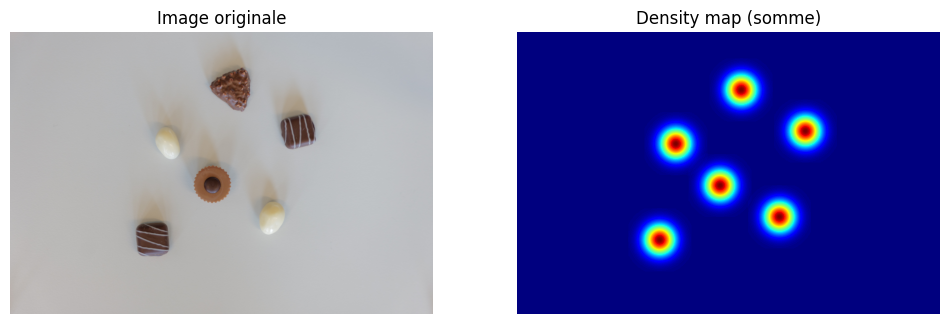

Nombre estimé d'objets sur l'image : 5.918


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# exemple de chargement d'une density map et de l'image correspondante
npz = np.load("density_maps/L1000756.npz")
density = npz["density"]    # shape (H, W, n_classes)
img = cv2.imread("dataset_project_iapr2025/train/L1000756.JPG")[:,:,::-1]

# visualisation de la somme sur les canaux (densité totale)
total_density = density.sum(axis=-1)

fig, axes = plt.subplots(1,2, figsize=(12,5))
axes[0].imshow(img); axes[0].set_title("Image originale"); axes[0].axis("off")
axes[1].imshow(total_density, cmap="jet"); axes[1].set_title("Density map (somme)"); axes[1].axis("off")
plt.show()

# vérifiez aussi la somme pour estimer le nombre d'objets
print("Nombre estimé d'objets sur l'image :", total_density.sum())
